# Value Sub-Metric: The Best Neighborhood In Pittsburgh

**Team Name:** Best Burgh

**By:** Yixin Li

## Introduction

**Project Background:** In this project, our goal is to identify the "best" neighborhood in Pittsburgh using data. "Best" can be defined across various dimensions, such as safety, educational resources, convenience, or economic vitality.

**My Approach and Metric Selection:** We posit that property valuations and market values ​​serve as strong indicators of a neighborhood’s overall appeal, the quality of its infrastructure, and the economic affluence of its residents. Consequently, we have chosen the number of homes valued at $500,000 or more as the primary metric to gauge a neighborhood's strengths. A higher concentration of high-value properties generally suggests a superior neighborhood environment and better public amenities.

**Alternative Approaches Considered:** Before settling on this metric, I explored several other options:

Option 1 - Crime Rate Datasets: While these reflect safety, the data for some neighborhoods may suffer from statistical bias or incompleteness.

Option 2 - Park and Green Space Area: Although this serves as an indicator of livability, it fails to capture economic vitality or overall standard of living.
Given the need for both data integrity and intuitive interpretation, I ultimately selected property value as the core evaluation criterion.

**Dataset:** Pittsburgh American Community Survey 2015 - Miscellaneous Data - Housing Unit Value

**Link:** https://data.wprdc.org/dataset/5b18c198-474c-4723-b735-cc5220ad43cc/resource/13982f58-e618-400c-8f69-6a32dbd7c68f/

## The Metric

**Metric Description:** Our primary metric is the "Total Number of High-Value Homes" (High_Value_Total).

**Characteristics Measured:** This metric encompasses the following high-value property brackets:

$500,000 to $749,999

$750,000 to $999,999

$1,000,000 to $1,499,999

$1,500,000 to $1,999,999

$2,000,000 or more

**Data Source:** We utilized a housing value dataset from the Western Pennsylvania Regional Data Center (WPRDC). Using the Pandas library, we processed the columns representing these high-value property categories and aggregated the totals by neighborhood.

**Link:** https://data.wprdc.org/dataset/5b18c198-474c-4723-b735-cc5220ad43cc/resource/13982f58-e618-400c-8f69-6a32dbd7c68f/

Matplotlib is building the font cache; this may take a moment.


                 Neighborhood  High_Value_Total
76        Squirrel Hill North             734.0
77        Squirrel Hill South             590.0
68                  Shadyside             407.0
63               Point Breeze             251.0
16  Central Business District              80.0
53           Mount Washington              73.0
39              Highland Park              61.0
56              North Oakland              57.0
84                  Troy Hill              41.0
13                  Brookline              41.0


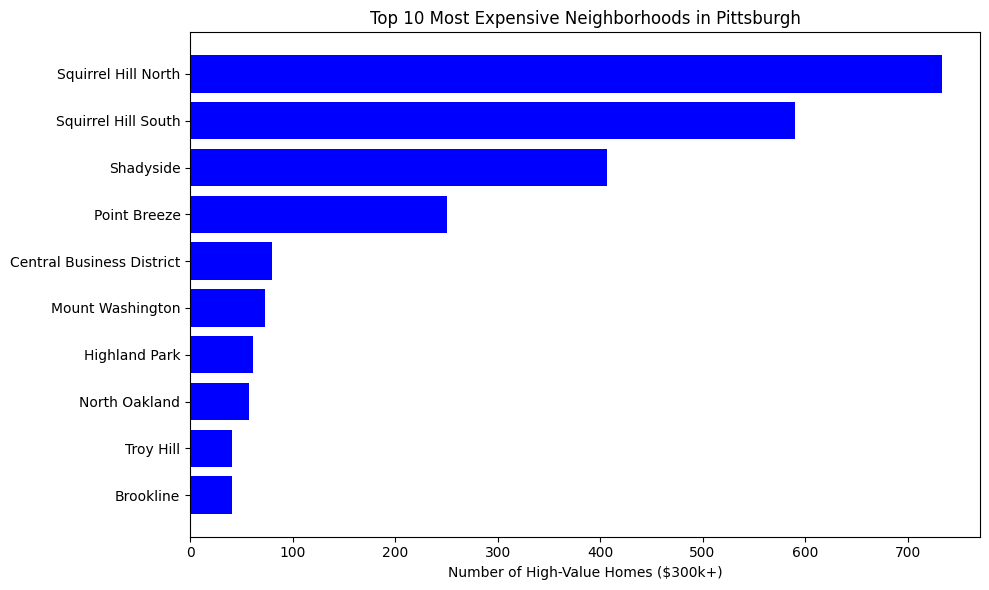

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load the dataset from the file named 'value.csv'
df = pd.read_csv("value.csv")


# Find all of the houses that above $500,000
high_value_cols = [
    "Estimate; Total: - $500,000 to $749,999",
    "Estimate; Total: - $750,000 to $999,999",
    "Estimate; Total: - $1,000,000 to $1,499,999",
    "Estimate; Total: - $1,500,000 to $1,999,999",
    "Estimate; Total: - $2,000,000 or more",
]

# Ensure columns are numeric; convert errors to NaN and fill with 0
for col in high_value_cols:
  df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

# Calculate the total number of high-value homes per neighborhood
df["High_Value_Total"] = df[high_value_cols].sum(axis=1)

# Find the top 10 most expensive neighborhoods
top_expensive_neighborhoods = df[["Neighborhood", "High_Value_Total"]].sort_values(
    by="High_Value_Total", ascending=False
)

print(top_expensive_neighborhoods.head(10))
# Graph top 10
top10 = top_expensive_neighborhoods.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top10["Neighborhood"][::-1],
    top10["High_Value_Total"][::-1],
    color="blue",
)
plt.xlabel("Number of High-Value Homes ($300k+)")
plt.title("Top 10 Most Expensive Neighborhoods in Pittsburgh")
plt.tight_layout()

# Graph
plt.show()

## The Best Neighborhood

Based on the code we developed and the resulting data visualizations, the best neighborhood in Pittsburgh has been identified:

**Data Findings:** Squirrel Hill North ranks first (with 734 high-value homes), followed by Squirrel Hill South (590 homes) and Shadyside (407 homes).

**Clear Lead:** As shown in the horizontal bar chart, Squirrel Hill North significantly outpaces other neighborhoods in terms of the number of high-value properties.

**Analysis:** Squirrel Hill has long been recognized as a premier residential area in Pittsburgh. With its well-established commercial districts, convenient transportation, and proximity to world-class institutions like Carnegie Mellon University (CMU) and the University of Pittsburgh (Pitt), the neighborhood attracts a large number of high-income individuals, academics, and professionals. The high property valuations objectively reflect the area’s strong economic foundation and exceptional quality of life.

## Conclusion

**Data Results:** The top two neighborhoods are Squirrel Hill North (with 734 high-value homes) and Squirrel Hill South (590 homes), followed by Shadyside (407 homes) and Point Breeze (251 homes).

As shown in the horizontal bar chart, Squirrel Hill North and South significantly outpace other neighborhoods in terms of the number of high-value properties.

**Analysis:** Squirrel Hill features well-established commercial districts and convenient transportation. Its proximity to world-class institutions—such as Carnegie Mellon University (CMU) and the University of Pittsburgh (Pitt)—attracts a large number of high-income individuals and academics. The high property valuations are an objective reflection of the quality of the neighborhood.

**Reflection:** My personal favorite neighborhood is Shadyside, which ranks third with 407 high-value homes and is right behind both Squirrel Hill neighborhoods. This gap shows the difference between a data-driven ranking differs from personal preference. Both agree that Shadyside is a strong neighborhood, but the data puts Squirrel Hill on top because it has more high-value homes, not because it is a better place to live.